# Conformal prediction under distribution shift

Split conformal methods pool the last `n_windows` calibration errors and take one quantile of them. That
works when future errors look like past errors. When the error scale changes (a new regime, a surge), the
pooled quantile reacts slowly because most calibration windows still describe the old regime.

**Conformal PID control** ([Angelopoulos, Candes & Tibshirani, 2023](https://arxiv.org/abs/2307.16895)) replays the same
calibration windows in time order and *tracks* the error quantile online: a proportional step moves it after every
miss, and an integral term reacts to accumulated miscoverage. In `foundationforecast` it is a method object:
`ConformalIntervals(method=PID(...))`.

This notebook backtests pooled conformal and PID on the same point forecasts of a real dataset with a real
shift: **weekly COVID-19 cases across countries**, the setting used to study conformal prediction under
distribution shift (the PID paper evaluates on COVID-19 forecasts, and conformal time-series work such as CF-RNN uses COVID-19 data too). For the other conformal methods see the
[conformal prediction example](conformal-prediction.ipynb) and the
[conformal prediction guide](../conformal-prediction.md).

In [ ]:
!UV_CONSTRAINT= UV_BUILD_CONSTRAINT= uv pip install -q "foundationforecast[plot]"

## Load the data

**Dataset:** weekly new confirmed COVID-19 cases from the
[JHU CSSE COVID-19 data repository](https://github.com/CSSEGISandData/COVID-19) (CC BY 4.0, archived March 2023).
We summed daily new cases (differences of the cumulative counts, negative corrections clipped to zero) into
Sunday-ending weeks, and kept the 68 countries that report throughout: at most 10% zero weeks overall and no zero weeks
after September 2021. The prepared panel is hosted on S3 with the standard columns `unique_id`, `ds` and `y`.

We stop the data at the end of September 2022, so the backtest below ends there.

In [ ]:
import numpy as np
import pandas as pd

from foundationforecast import PID, ConformalIntervals, FoundationForecast
from foundationforecast.models import Chronos

df = pd.read_parquet(
    "https://timecopilot.s3.amazonaws.com/public/data/covid19-weekly-cases.parquet"
)
df = df[df["ds"] <= "2022-09-25"].reset_index(drop=True)
df["unique_id"].nunique(), df["ds"].min().date(), df["ds"].max().date()

(68, datetime.date(2020, 2, 2), datetime.date(2022, 9, 25))

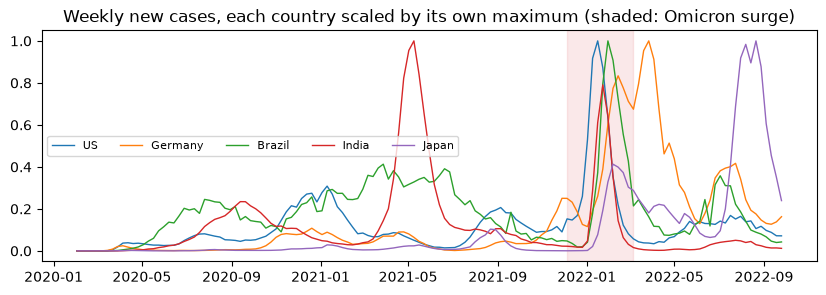

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 3))
for uid in ["US", "Germany", "Brazil", "India", "Japan"]:
    g = df[df["unique_id"] == uid]
    ax.plot(g["ds"], g["y"] / g["y"].max(), label=uid, lw=1)
ax.axvspan(pd.Timestamp("2021-12-05"), pd.Timestamp("2022-03-06"), color="tab:red", alpha=0.1)
ax.set_title("Weekly new cases, each country scaled by its own maximum (shaded: Omicron surge)")
ax.legend(ncol=5, fontsize=8)
plt.show()

## Backtest setup

- **Horizon:** 4 weeks, as in the COVID-19 Forecast Hub.
- **Evaluation:** 16 windows with a 4-week step, 64 weeks in total, ending in September 2022. They cover the stable
  period before Omicron and the Omicron surge of December 2021 to February 2022, when case counts jumped several-fold in
  most countries within a few weeks.
- **Calibration:** the last 12 non-overlapping 4-week windows before each evaluation cutoff (`n_windows=12`, `step_size=4`), i.e.
  the previous 48 weeks. Each window is calibrated only on data that ended before its cutoff.
- **Point forecaster:** Chronos-Bolt small. All four models share it; only the calibration method differs.

The calibrators:

- `conformal_distribution` and `conformal_error`: pooled split conformal (library defaults).
- `PID()`: quantile tracking plus error integration, asymmetric tails.
- `PID(integrate=False)`: quantile tracking only.

In [ ]:
H, N_EVAL, N_CAL, level = 4, 16, 12, [80, 95]

settings = {
    "conformal_distribution": ConformalIntervals(
        n_windows=N_CAL, method="conformal_distribution", step_size=H
    ),
    "conformal_error": ConformalIntervals(
        n_windows=N_CAL, method="conformal_error", step_size=H
    ),
    "PID": ConformalIntervals(n_windows=N_CAL, method=PID(), step_size=H),
    "PID-no-integrator": ConformalIntervals(
        n_windows=N_CAL, method=PID(integrate=False), step_size=H
    ),
}
ff = FoundationForecast(
    models=[
        Chronos(repo_id="amazon/chronos-bolt-small", alias=alias, prediction_intervals=ci)
        for alias, ci in settings.items()
    ]
)

In [ ]:
cv = ff.cross_validation(
    df=df, h=H, n_windows=N_EVAL, step_size=H, freq="W-SUN", level=level
)
cv["window"] = cv.groupby("unique_id")["cutoff"].rank(method="dense").astype(int)
cv.groupby("window")["cutoff"].first().dt.date.rename("cutoff").to_frame().T

window,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
cutoff,2021-07-04,2021-08-01,2021-08-29,2021-09-26,2021-10-24,2021-11-21,2021-12-19,2022-01-16,2022-02-13,2022-03-13,2022-04-10,2022-05-08,2022-06-05,2022-07-03,2022-07-31,2022-08-28


## Evaluation

**Coverage** is the share of actuals inside the interval; a calibrated \(L\)% interval should cover about \(L\)%.
**MSIS** is the mean scaled interval score (Gneiting & Raftery; lower is better): interval width plus a penalty
proportional to \(2/\alpha\) for every unit an actual falls outside, scaled by each series' naive one-week
MAE on the data before the backtest. It rewards narrow intervals only if they still cover.

We report two phases: the windows **before** the surge (cutoffs before 2021-11-28, whose targets are before the Omicron wave)
and the windows **during and after** it.

In [ ]:
train = df[df["ds"] < cv["cutoff"].min()]
scale = train.groupby("unique_id")["y"].apply(lambda s: s.diff().abs().mean())
surge_start = pd.Timestamp("2021-11-28")
cv["phase"] = np.where(cv["cutoff"] < surge_start, "before surge", "surge and after")


def summarize(cv):
    rows = []
    s = cv["unique_id"].map(scale)
    for alias in settings:
        for lv in level:
            lo, hi, y = cv[f"{alias}-lo-{lv}"], cv[f"{alias}-hi-{lv}"], cv["y"]
            width = (hi - lo) / s
            miss = (np.maximum(lo - y, 0) + np.maximum(y - hi, 0)) / s
            for phase, idx in cv.groupby("phase").groups.items():
                rows.append(
                    {
                        "phase": phase,
                        "method": alias,
                        "level": lv,
                        "coverage": y[idx].between(lo[idx], hi[idx]).mean(),
                        "msis": (width[idx] + 2 / (1 - lv / 100) * miss[idx]).mean(),
                    }
                )
    return pd.DataFrame(rows)


summary = summarize(cv)
cols = ["phase", "level"]
order = list(settings)
summary.pivot_table(index="method", columns=cols, values="coverage").loc[order].round(3)

phase                  before surge        surge and after       
level                            80     95              80     95
method                                                           
conformal_distribution        0.688  0.818           0.703  0.839
conformal_error               0.691  0.819           0.709  0.840
PID                           0.825  0.926           0.847  0.921
PID-no-integrator             0.640  0.711           0.681  0.736

In [ ]:
summary.pivot_table(index="method", columns=cols, values="msis").loc[order].round(2)

phase                  before surge         surge and after         
level                            80      95              80       95
method                                                              
conformal_distribution        87.84  195.22          983.24  2948.64
conformal_error               87.61  193.43          987.14  2926.49
PID                           92.69  186.93         1435.41  3393.61
PID-no-integrator            100.66  348.81          959.32  3424.12

**Reading the results:**
- **Before the surge** the pooled methods already undercover (about 0.69 at 80% and 0.82 at 95%): weekly case counts are noisy
  and growing or shrinking waves make the next four weeks differ from the last 48. `PID()` is closer to nominal
  (0.83 / 0.93).
- **Around and after the surge** pooled coverage stays at 0.71 / 0.84 on average, but that mixes the surge with the
  decay afterwards (see the plot). `PID()` has 0.85 / 0.92.
- **The integrator is what reacts.** `PID(integrate=False)` tracks quantiles only and is no better than pooled
  conformal (0.68 / 0.74 after the surge started).
- **PID is not cheaper.** Its intervals are much wider, and mean MSIS is not better than pooled conformal here
  (for example 1435 vs 987 at 80% in the second phase). MSIS on counts is dominated by a few countries with large
  errors, so also look at coverage by window.

## Coverage by evaluation window

The averages hide the dynamics. Here is the coverage of each evaluation window, averaged over countries and horizon
steps, with the shaded windows being those whose forecast origin falls in the Omicron surge.

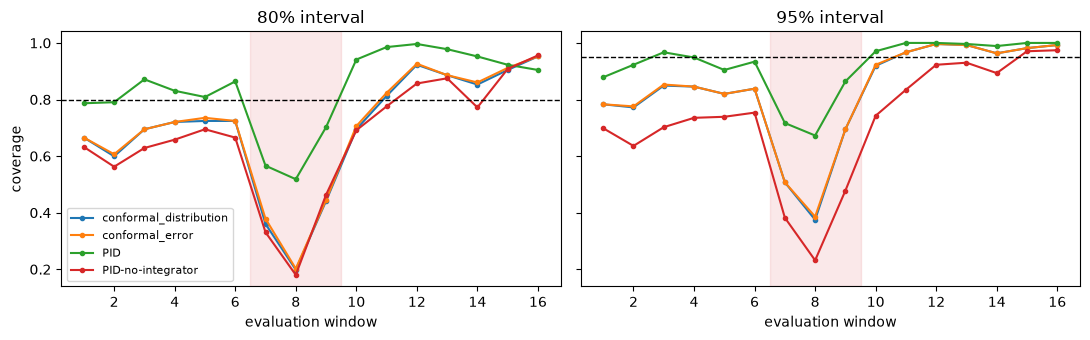

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
surge_windows = cv.loc[
    (cv["cutoff"] >= surge_start) & (cv["cutoff"] <= "2022-02-27"), "window"
].unique()
for ax, lv in zip(axes, level):
    for alias in settings:
        lo, hi = cv[f"{alias}-lo-{lv}"], cv[f"{alias}-hi-{lv}"]
        cov = cv["y"].between(lo, hi).groupby(cv["window"]).mean()
        ax.plot(cov.index, cov.values, marker="o", ms=3, label=alias)
    ax.axhline(lv / 100, color="k", ls="--", lw=1)
    ax.axvspan(surge_windows.min() - 0.5, surge_windows.max() + 0.5, color="tab:red", alpha=0.1)
    ax.set_title(f"{lv}% interval")
    ax.set_xlabel("evaluation window")
axes[0].set_ylabel("coverage")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Reading the plot:**
- Windows 7 to 9 are the surge. For the pooled methods coverage collapses to a minimum of about 0.20 at 80% and 0.39
  at 95% (window 8): the 12 calibration windows only contain the quieter regime. `PID()` also undercovers there, with
  a minimum of about 0.52 and 0.67, but recovers noticeably faster and loses far less.
- After the surge the situation reverses. All methods over-cover, and PID more so (it stays above 0.9 at 80% and close to 1.0 at 95%
  for several windows), because its threshold needs time to come back down.
- Treat this as a descriptive result on one dataset and one regime change, not a coverage guarantee. The advantage is on
  coverage during the shift, paid for with wider intervals before and after it.

## When to use PID

Use `PID()` when the error scale of your series can change between the calibration period and the forecast
period and a loss of coverage is costlier than wider intervals: epidemic waves, volatility regimes, demand shocks.
Stay with the pooled methods when errors are stable and you want the tightest intervals.

- `PID(integrate=False)` gives tighter intervals but does not react to a sustained shift.
- `PID(symmetric=True)` tracks absolute errors with one threshold instead of separate lower and upper tails.
- **Calibration windows matter.** We use non-overlapping windows (`step_size=h`). In a check with 20 weekly-overlapping windows
  (`step_size=1`, `h=4`) on this same panel, the integrator saturated and about 30% of the default `PID()` intervals were
  infinite, because neighbouring windows have strongly correlated errors. When the integrator saturates, some bounds become infinite
  and `forecast()` emits a `UserWarning`: use more or non-overlapping windows, raise `Csat` or `Tg`, or set `integrate=False`.
- Check the achieved coverage and interval width on your own backtest, as done here.

See the [conformal prediction guide](../conformal-prediction.md#conformal-pid-control-under-distribution-shift) for the
update rule, every `PID` parameter, the delayed-feedback handling and the R cross-check.